# Learning land-surface temperature from TESSERA embeddings

[TESSERA](https://github.com/ucam-eo/tessera) is a foundation model that compresses a whole
year of Sentinel-1 radar and Sentinel-2 optical observations into **128 numbers per 10 m
pixel**, an *embedding*. The embedding is not a physical quantity: it is a description of
how a pixel looks and changes through the year, learnt so that similar surfaces get similar
numbers. The promise is that a simple model on top of it can learn almost any surface
property from a modest number of labelled pixels.

This notebook tests that promise on a variable TESSERA never saw: **summer daytime
land-surface temperature (LST)**. Neither Sentinel-1 nor Sentinel-2 measures temperature
(they have no thermal band), so the model can only learn it indirectly, from what the
embedding knows about the surface: buildings and asphalt, irrigated or dry fields, trees,
water.

The recipe:

1. draw two neighbouring polygons around Seville (Spain): one to **train** on, one to
   **test** on;
2. for each, fetch the 2024 TESSERA embeddings and the summer 2024 Landsat surface
   temperature with cubesip;
3. put both on the same 30 m grid, one row per pixel: 128 embedding values (inputs) and one
   temperature (target);
4. fit a linear model and a random forest on the training polygon;
5. predict the test polygon, which the models have never seen, and compare with what
   Landsat measured.

Along the way it shows why the score you get from a random split of the training pixels is
too optimistic for remote sensing, and how to get an honest one.

**Before running.** Install the `tessera` extra and the `examples` group
(`uv sync --extra tessera --group examples`) and have a `cubesip.yaml` with a Copernicus
Data Space account (`openeo` section): the Landsat data are read from Microsoft Planetary
Computer by the CDSE openEO back-end. The first run downloads about 160 MB and takes a
minute or two; later runs read the files back from `data/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
from pyproj import CRS, Transformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import cubesip
from cubesip.processing import containing_geohash, mask_to_polygon, regrid
from cubesip.spatial import native_crs

# cubesip.yaml and data/ are in the repository root; Jupyter starts in the notebook's folder.
if Path.cwd().name == "examples":
    os.chdir(Path.cwd().parent)

# Chart colours (light theme), as in the other examples.
SURFACE = "#fcfcfb"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
TRAIN_COLOUR = "#2a78d6"
TEST_COLOUR = "#d95f02"


def grid_crs(da: xr.DataArray) -> str:
    # CRS of a DataArray's grid, e.g. 'EPSG:32629'.
    return native_crs(da.to_dataset(name="v"))


plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
    }
)

## 1. Two neighbouring polygons

Seville has some of the hottest summers in Europe and, within a few kilometres, very
different surfaces: the dense old town, newer districts with wide roads, parks, the
Guadalquivir river and its canal, and farmland that in July is either irrigated (green and
relatively cool) or harvested and bone dry (often hotter than the city itself).

The **training polygon** covers central and south-western Seville; the **test polygon** lies
just south of it, along the same river, with a similar but not identical mix of surfaces.
Both are written as WKT in EPSG:4326 with **longitude first**, as every cubesip function
expects.

In [2]:
TRAIN_WKT = (
    "POLYGON ((-6.017 37.356, -5.980 37.357, -5.979 37.394, "
    "-6.000 37.395, -6.018 37.388, -6.017 37.356))"
)
TEST_WKT = (
    "POLYGON ((-6.016 37.315, -5.985 37.312, -5.979 37.335, "
    "-5.981 37.351, -6.015 37.350, -6.016 37.315))"
)
YEAR = 2024

polygons = {"train": TRAIN_WKT, "test": TEST_WKT}
sites = {name: containing_geohash(wkt) for name, wkt in polygons.items()}

# Area in km2, measured in the local UTM zone (30N).
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32630", always_xy=True)
for name, wkt in polygons.items():
    shape = shapely.transform(
        shapely.from_wkt(wkt), lambda xy: np.column_stack(to_utm.transform(xy[:, 0], xy[:, 1]))
    )
    print(f"{name:>5}: {shape.area / 1e6:.1f} km2, geohash cell {sites[name]}")

train: 13.7 km2, geohash cell eyesx
 test: 12.6 km2, geohash cell eyesr


cubesip addresses areas by [geohash](https://en.wikipedia.org/wiki/Geohash) cell, so each
polygon is fetched as the smallest cell that contains it and cut out afterwards.

Keep each polygon inside a **5-character cell** (about 4 x 5 km here). TESSERA embeddings
are big, 128 float values per 10 m pixel, and the driver reads the whole cell into memory:
about 100 MB for a 5-character cell, but almost 3 GB for a 4-character one. A polygon that
straddles the edge of two 5-character cells falls back to the 4-character cell around them,
which the next line catches.

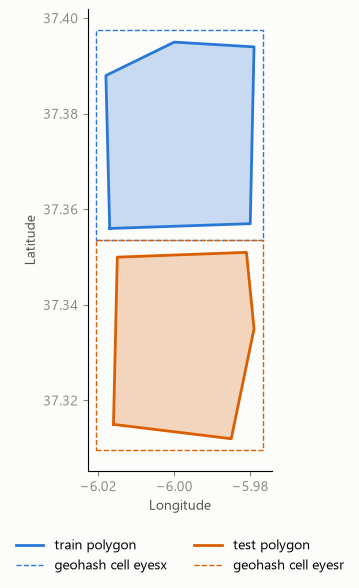

In [3]:
assert all(len(site) >= 5 for site in sites.values()), "a polygon crosses a level-5 cell edge"

fig, ax = plt.subplots(figsize=(5, 6))
for name, colour in (("train", TRAIN_COLOUR), ("test", TEST_COLOUR)):
    shape = shapely.from_wkt(polygons[name])
    ax.fill(*shape.exterior.xy, color=colour, alpha=0.25, linewidth=0)
    ax.plot(*shape.exterior.xy, color=colour, linewidth=2, label=f"{name} polygon")
    cell = cubesip.geohash.bbox(sites[name])
    ax.plot(
        [cell.west, cell.east, cell.east, cell.west, cell.west],
        [cell.south, cell.south, cell.north, cell.north, cell.south],
        color=colour,
        linewidth=1,
        linestyle="--",
        label=f"geohash cell {sites[name]}",
    )
ax.set_aspect(1 / np.cos(np.radians(37.35)))  # metres look square
ax.set_xlabel("Longitude", color=INK_SECONDARY)
ax.set_ylabel("Latitude", color=INK_SECONDARY)
ax.tick_params(colors=INK_MUTED)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, ncols=2)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## 2. Fetching the data

Two requests per polygon:

- **TESSERA embeddings** for 2024 (`tessera` driver). An embedding summarises a whole
  year, so the request must cover whole calendar years. Public data, no account needed.
- **Landsat 8 and 9 Collection 2 Level-2** surface temperature (`lwir11`) and the
  cloud mask (`qa_pixel`) for June to August 2024 (`stac` driver: the Planetary Computer
  catalogue, read by openEO on the Copernicus Data Space).

`cubesip.check` says what each request would download; `cubesip.run` downloads it (or
reuses the cached file) and opens it as a lazy `xarray.Dataset`.

Two messages may show up on the first run, both harmless here: openEO notes that
`qa_pixel` is not in the band list of the collection's metadata (it is in the files), and
geotessera notes that the geohash cell reaches across the edge of UTM zones 29 and 30 at
6° W and reads zone 30 only (the zone-30 tiles cover the whole cell, so no pixel is
missing).

In [4]:
def tessera_request(site: str) -> dict:
    return {
        "driver": "tessera",
        "dataset": "v1.1",
        "variables": ["embedding"],
        "geohash": site,
        "time": {"start": f"{YEAR}-01-01", "end": f"{YEAR}-12-31"},
        "target_dir": "data",
    }


def landsat_request(site: str) -> dict:
    return {
        "driver": "stac",
        "dataset": "https://planetarycomputer.microsoft.com/api/stac/v1/collections/landsat-c2-l2",
        "variables": ["lwir11", "qa_pixel"],
        "geohash": site,
        "time": {"start": f"{YEAR}-06-01", "end": f"{YEAR}-08-31"},
        "target_dir": "data",
        "options": {"max_cloud_cover": 50},
    }


requests = {
    (name, kind): make(site)
    for name, site in sites.items()
    for kind, make in (("tessera", tessera_request), ("landsat", landsat_request))
}
for request in requests.values():
    print(cubesip.check(request), end="\n\n")

cubesip check: tessera v1.1 [embedding] @ eyesx, 2024-01-01 to 2024-12-31
  status : cached (geohash eyesx) in C:\Users\matte\OneDrive\local\work\cubesip\data\tessera_v1-1-dclimate_eyesx_20240101-20241231_a27c02b7.nc

cubesip check: stac https://planetarycomputer.microsoft.com/api/stac/v1/collections/landsat-c2-l2 [lwir11, qa_pixel] @ eyesx, 2024-06-01 to 2024-08-31
  status : cached (geohash eyesx) in C:\Users\matte\OneDrive\local\work\cubesip\data\stac_landsat-c2-l2_eyesx_20240601-20240831_a6a5e9bf.nc

cubesip check: tessera v1.1 [embedding] @ eyesr, 2024-01-01 to 2024-12-31
  status : cached (geohash eyesr) in C:\Users\matte\OneDrive\local\work\cubesip\data\tessera_v1-1-dclimate_eyesr_20240101-20241231_a27c02b7.nc

cubesip check: stac https://planetarycomputer.microsoft.com/api/stac/v1/collections/landsat-c2-l2 [lwir11, qa_pixel] @ eyesr, 2024-06-01 to 2024-08-31
  status : cached (geohash eyesr) in C:\Users\matte\OneDrive\local\work\cubesip\data\stac_landsat-c2-l2_eyesr_20240601-20

In [5]:
results = {}
for key, request in requests.items():
    results[key] = cubesip.run(request)
    origin = "from cache" if results[key].from_cache else "downloaded"
    print(f"{key[0]:>5} {key[1]:<8} {origin}: {results[key].path.name}")

train tessera  from cache: tessera_v1-1-dclimate_eyesx_20240101-20241231_a27c02b7.nc


train landsat  from cache: stac_landsat-c2-l2_eyesx_20240601-20240831_a6a5e9bf.nc


 test tessera  from cache: tessera_v1-1-dclimate_eyesr_20240101-20241231_a27c02b7.nc


 test landsat  from cache: stac_landsat-c2-l2_eyesr_20240601-20240831_a6a5e9bf.nc


## 3. The target: summer land-surface temperature

Landsat stores surface temperature as integers: kelvin = DN x 0.00341802 + 149.0 (the
`scale` and `offset` of the STAC metadata), with 0 for missing data. A pixel is kept when
`qa_pixel` bit 6 (clear) is set and bits 4 (cloud shadow) and 5 (snow) are not.

The target is the **mean over the summer of each pixel's clear-sky temperature**, taken as
the mean of the June, July and August means so that a month with more clear scenes does not
weigh more. These are late-morning surface temperatures (the Landsat overpass is at about
10:30 solar time):
in the Andalusian summer a dry field or a roof can be 20 °C hotter than a well-watered lawn.

Landsat's thermal sensor sees 100 m pixels, which USGS resamples to the 30 m grid of the
optical bands. Keep this in mind: neighbouring 30 m pixels are not independent
measurements.

In [6]:
def summer_lst(result: cubesip.Result) -> xr.DataArray:
    # Mean summer clear-sky land-surface temperature (°C), as the mean of monthly means.
    ds = result.dataset
    qa = ds["qa_pixel"].fillna(1).astype("uint16")  # 1 = fill in QA_PIXEL
    bit = lambda n: (qa & (1 << n)) > 0  # noqa: E731
    clear_sky = bit(6) & ~bit(4) & ~bit(5)
    dn = ds["lwir11"]
    lst = (dn * 0.00341802 + 149.0 - 273.15).where(clear_sky & (dn > 0))
    n_clear = int(clear_sky.any(["y", "x"]).sum())
    print(f"{result.path.name}: {ds.sizes['t']} scenes, {n_clear} with clear pixels")
    summer = lst.resample(t="MS").mean().mean("t").compute()
    summer.name = "LST"
    return summer


lst = {name: summer_lst(results[(name, "landsat")]) for name in polygons}

stac_landsat-c2-l2_eyesx_20240601-20240831_a6a5e9bf.nc: 10 scenes, 10 with clear pixels
stac_landsat-c2-l2_eyesr_20240601-20240831_a6a5e9bf.nc: 10 scenes, 9 with clear pixels


## 4. The inputs: embeddings on the Landsat grid

The embeddings are on a 10 m grid, the temperature on a 30 m one. Rather than inventing
temperature detail that Landsat does not have, the embeddings are **averaged** onto the
Landsat grid with `regrid(..., method="average")`: each 30 m pixel gets the mean of the
10 m embeddings that fall inside it, about nine. The two grids are not even in the same
projection: TESSERA uses UTM zone 30N (the zone of the geohash centre), while these Landsat
scenes are in zone 29N, as Seville lies just east of the 6° W zone edge. `regrid`
reprojects on the way.

The embeddings' first three principal components, shown as red, green and blue, give a
feel for what the 128 numbers encode: without being told anything about temperature, they
already separate the river, the parks, the built-up areas and the different fields.

In [7]:
features = {}
for name in polygons:
    embedding = results[(name, "tessera")].dataset["embedding"].isel(time=0, drop=True)
    features[name] = regrid(embedding, lst[name], method="average").compute()

crs = CRS.from_user_input(grid_crs(lst["train"])).name
print(f"Training polygon features: {dict(features['train'].sizes)}, on the Landsat grid ({crs})")

Training polygon features: {'band': 128, 'y': 168, 'x': 136}, on the Landsat grid (WGS 84 / UTM zone 29N)


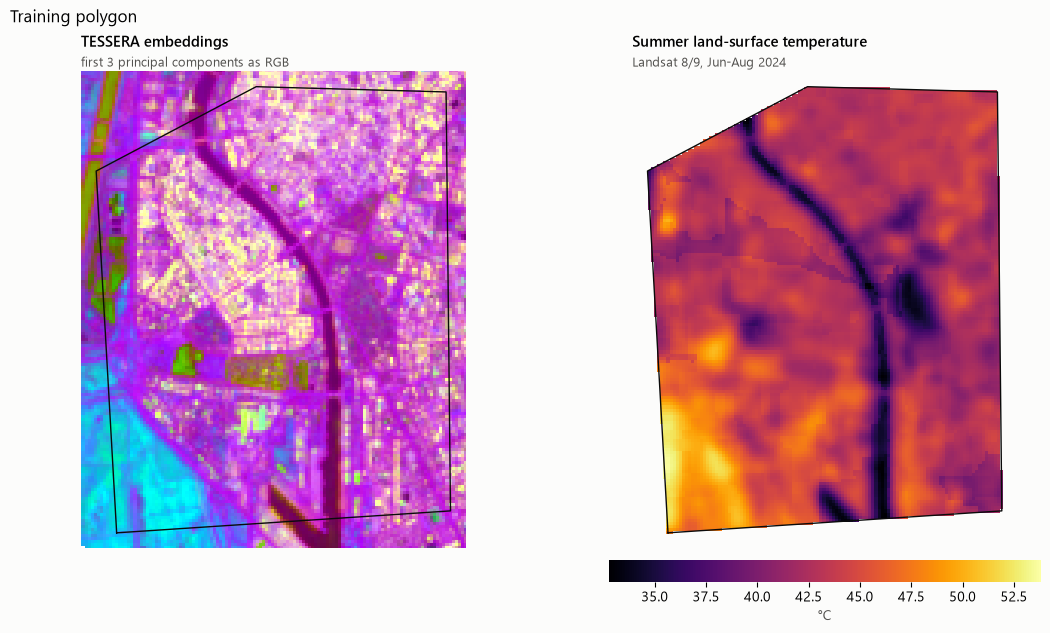

In [8]:
def outline_on_grid(wkt: str, grid: xr.DataArray) -> shapely.Geometry:
    # The polygon in the grid's CRS, to draw it on a map.
    to_grid = Transformer.from_crs("EPSG:4326", grid_crs(grid), always_xy=True)
    return shapely.transform(
        shapely.segmentize(shapely.from_wkt(wkt), 0.001),
        lambda xy: np.column_stack(to_grid.transform(xy[:, 0], xy[:, 1])),
    )


def style_map(ax, outline, title, subtitle=None):
    ax.plot(*outline.exterior.xy, color=INK_PRIMARY, linewidth=1)
    west, south, east, north = outline.buffer(150).bounds
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"{title}\n", loc="left", fontsize=11, fontweight="semibold")
    if subtitle:
        ax.text(0, 1.01, subtitle, transform=ax.transAxes, color=INK_SECONDARY, fontsize=9)


def false_colour(emb: xr.DataArray, pca: PCA) -> np.ndarray:
    # First three principal components of the embeddings as an RGB image (NaN -> white).
    values = emb.transpose("y", "x", "band").values
    valid = ~np.isnan(values).any(axis=-1)
    rgb = np.ones((*valid.shape, 3))
    pcs = pca.transform(values[valid])
    lo, hi = np.percentile(pcs, [2, 98], axis=0)
    rgb[valid] = np.clip((pcs - lo) / (hi - lo), 0, 1)
    return rgb


train_values = features["train"].transpose("y", "x", "band").values.reshape(-1, 128)
pca = PCA(n_components=3).fit(train_values[~np.isnan(train_values).any(axis=1)])

name = "train"
outline = outline_on_grid(polygons[name], lst[name])
inside = mask_to_polygon(lst[name], polygons[name])
fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), layout="constrained")
emb = features[name]
axes[0].imshow(
    false_colour(emb, pca),
    extent=[
        float(emb.x.min()) - 15,
        float(emb.x.max()) + 15,
        float(emb.y.min()) - 15,
        float(emb.y.max()) + 15,
    ],
    origin="upper" if emb.y[0] > emb.y[-1] else "lower",
)
style_map(axes[0], outline, "TESSERA embeddings", "first 3 principal components as RGB")
mesh = axes[1].pcolormesh(inside.x, inside.y, inside, cmap="inferno", shading="nearest")
style_map(axes[1], outline, "Summer land-surface temperature", f"Landsat 8/9, Jun-Aug {YEAR}")
bar = fig.colorbar(mesh, ax=axes[1], orientation="horizontal", shrink=0.8, pad=0.02)
bar.set_label("°C", color=INK_SECONDARY)
bar.outline.set_visible(False)
fig.suptitle("Training polygon", x=0.01, ha="left", fontsize=12)
plt.show()

## 5. From maps to a table

Machine-learning libraries such as scikit-learn want a table: one row per sample, one
column per feature. Here a sample is a 30 m pixel **inside the polygon** with a valid
temperature and a full embedding. `X` has 128 columns, `y` is the temperature, and `where` remembers which
pixels the rows came from, to draw the predictions back on a map.

In [9]:
def pixel_table(name: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    target = mask_to_polygon(lst[name], polygons[name])  # NaN outside the polygon
    emb = features[name].transpose("y", "x", "band").values
    where = target.notnull().values & ~np.isnan(emb).any(axis=-1)
    return emb[where], target.values[where], where


tables = {name: pixel_table(name) for name in polygons}
X_train, y_train, _ = tables["train"]
X_test, y_test, test_where = tables["test"]

pd.DataFrame(
    {
        name: {
            "pixels": len(y),
            "mean LST (°C)": y.mean(),
            "std LST (°C)": y.std(),
            "5th percentile": np.percentile(y, 5),
            "95th percentile": np.percentile(y, 95),
        }
        for name, (_, y, _) in tables.items()
    }
).round(1)

,train,test
pixels,15237.0,13962.0
mean LST (°C),43.0,42.4
std LST (°C),3.1,4.7
5th percentile,37.1,32.3
95th percentile,48.5,48.5


The two polygons are similar on average, but the test polygon has a wider spread of
temperatures: more water at the cool end (the river is wider there) and a few very hot
bare fields. Predicting it will mean going beyond what the training polygon shows.

## 6. Three models

- a **baseline** that always predicts the mean temperature of the training pixels. Any
  model worth using must beat it; its error is the spread of the temperature itself;
- **ridge regression**, a linear model: the temperature as a weighted sum of the 128
  embedding values, with a penalty on large weights so that the many, correlated inputs do
  not overfit. The inputs are standardised first, and `RidgeCV` picks the penalty by
  cross-validation;
- a **random forest**, an average of a few hundred decision trees, which can capture
  non-linear relations and interactions between embedding values.

We score them with the root mean square error (**RMSE**, in °C: the typical size of an
error, large errors weighing more), the mean absolute error (**MAE**, °C) and **R²** (the
share of the temperature's variance the model explains: 1 is perfect, 0 is no better than
the baseline).

In [10]:
def make_models() -> dict:
    return {
        "baseline (mean)": None,
        "ridge regression": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13))),
        "random forest": RandomForestRegressor(
            n_estimators=300, min_samples_leaf=3, max_features=0.3, n_jobs=-1, random_state=0
        ),
    }


def fit_predict(model, X_fit, y_fit, X_new) -> np.ndarray:
    if model is None:  # the baseline
        return np.full(len(X_new), y_fit.mean())
    return model.fit(X_fit, y_fit).predict(X_new)


def scores(y_true, y_pred) -> dict:
    return {
        "RMSE (°C)": root_mean_squared_error(y_true, y_pred),
        "MAE (°C)": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
    }

### 6a. The usual first try: a random split

The textbook way to estimate how well a model generalises is to hold out a random 20 % of
the samples, fit on the other 80 % and score on the held-out part.

In [11]:
X_fit, X_held, y_fit, y_held = train_test_split(X_train, y_train, test_size=0.2, random_state=0)

random_split = {
    name: scores(y_held, fit_predict(model, X_fit, y_fit, X_held))
    for name, model in make_models().items()
}
pd.DataFrame(random_split).T.round(2)

,RMSE (°C),MAE (°C),R²
baseline (mean),3.18,2.22,-0.00
ridge regression,1.48,1.12,0.78
random forest,1.24,0.91,0.85


### 6b. A fairer check: hold out whole blocks

The random split is too kind. A held-out pixel almost always has a neighbour 30 m away in
the training set, and neighbours are near-copies: the thermal sensor's 100 m pixels span
about 3 x 3 Landsat pixels, and a field or a block of houses spans many more. The model can
score well by recognising the place rather than by learning what makes a surface hot.

Holding out **whole 300 m blocks** (10 x 10 pixels) instead puts some distance between
training and held-out pixels. Still the same area, but a step closer to predicting
somewhere new.

In [12]:
BLOCK = 10  # pixels: 300 m blocks

_, _, train_where = tables["train"]
rows, cols = np.nonzero(train_where)  # row and column of each training pixel
blocks = (rows // BLOCK) * 10_000 + cols // BLOCK  # one id per block

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
fit_idx, held_idx = next(split.split(X_train, y_train, groups=blocks))

block_split = {
    name: scores(
        y_train[held_idx], fit_predict(model, X_train[fit_idx], y_train[fit_idx], X_train[held_idx])
    )
    for name, model in make_models().items()
}
pd.DataFrame(block_split).T.round(2)

,RMSE (°C),MAE (°C),R²
baseline (mean),2.94,2.00,-0.01
ridge regression,1.55,1.19,0.72
random forest,1.35,1.05,0.79


## 7. The real test: the neighbouring polygon

Now each model is fitted on **all** the pixels of the training polygon and asked to predict
the test polygon, a different area it has never seen. This is how the model would be used:
labels where we have them, predictions where we do not.

In [13]:
models = make_models()
predictions = {name: fit_predict(model, X_train, y_train, X_test) for name, model in models.items()}
neighbour = {name: scores(y_test, pred) for name, pred in predictions.items()}

comparison = pd.concat(
    {
        "random split": pd.DataFrame(random_split).T,
        "block split": pd.DataFrame(block_split).T,
        "test polygon": pd.DataFrame(neighbour).T,
    },
    axis=1,
)
comparison.round(2)

random split                block split                 \
                    RMSE (°C) MAE (°C)    R²   RMSE (°C) MAE (°C)    R²   
baseline (mean)          3.18     2.22 -0.00        2.94     2.00 -0.01   
ridge regression         1.48     1.12  0.78        1.55     1.19  0.72   
random forest            1.24     0.91  0.85        1.35     1.05  0.79   

                 test polygon                 
                    RMSE (°C) MAE (°C)    R²  
baseline (mean)          4.72     3.57 -0.02  
ridge regression         3.00     2.34  0.59  
random forest            3.40     2.45  0.47

Read the table from left to right: the further the evaluation pixels are from the training
pixels, the larger the error. The random split flatters every model; the test polygon is
the honest answer. When you report the accuracy of a remote-sensing model, say how the
evaluation pixels were chosen.

Note also that **the ranking of the models changes**. Inside the training area the random
forest wins under both splits; on the new area the plain linear model does better. A
forest is very good at recognising surfaces it has seen many times, but it predicts by
averaging training temperatures, so it cannot go beyond the coolest and hottest training
pixels, and the test polygon has both cooler (more water) and hotter surfaces than the
training one (see the table in section 5). A linear model can extrapolate, for better or
worse. Model selection done inside one area can pick the wrong model for another.

The bias is worth a look too: a model can get the *pattern* right (hot here, cool there)
and still be off on average.

In [14]:
for name, pred in predictions.items():
    print(f"{name:<17} mean error (prediction - observation): {np.mean(pred - y_test):+.2f} °C")

baseline (mean)   mean error (prediction - observation): +0.65 °C
ridge regression  mean error (prediction - observation): +0.58 °C
random forest     mean error (prediction - observation): +1.12 °C


## 8. Maps of the prediction

Observed and predicted temperature over the test polygon, on the same colour scale, and
the difference for each model.

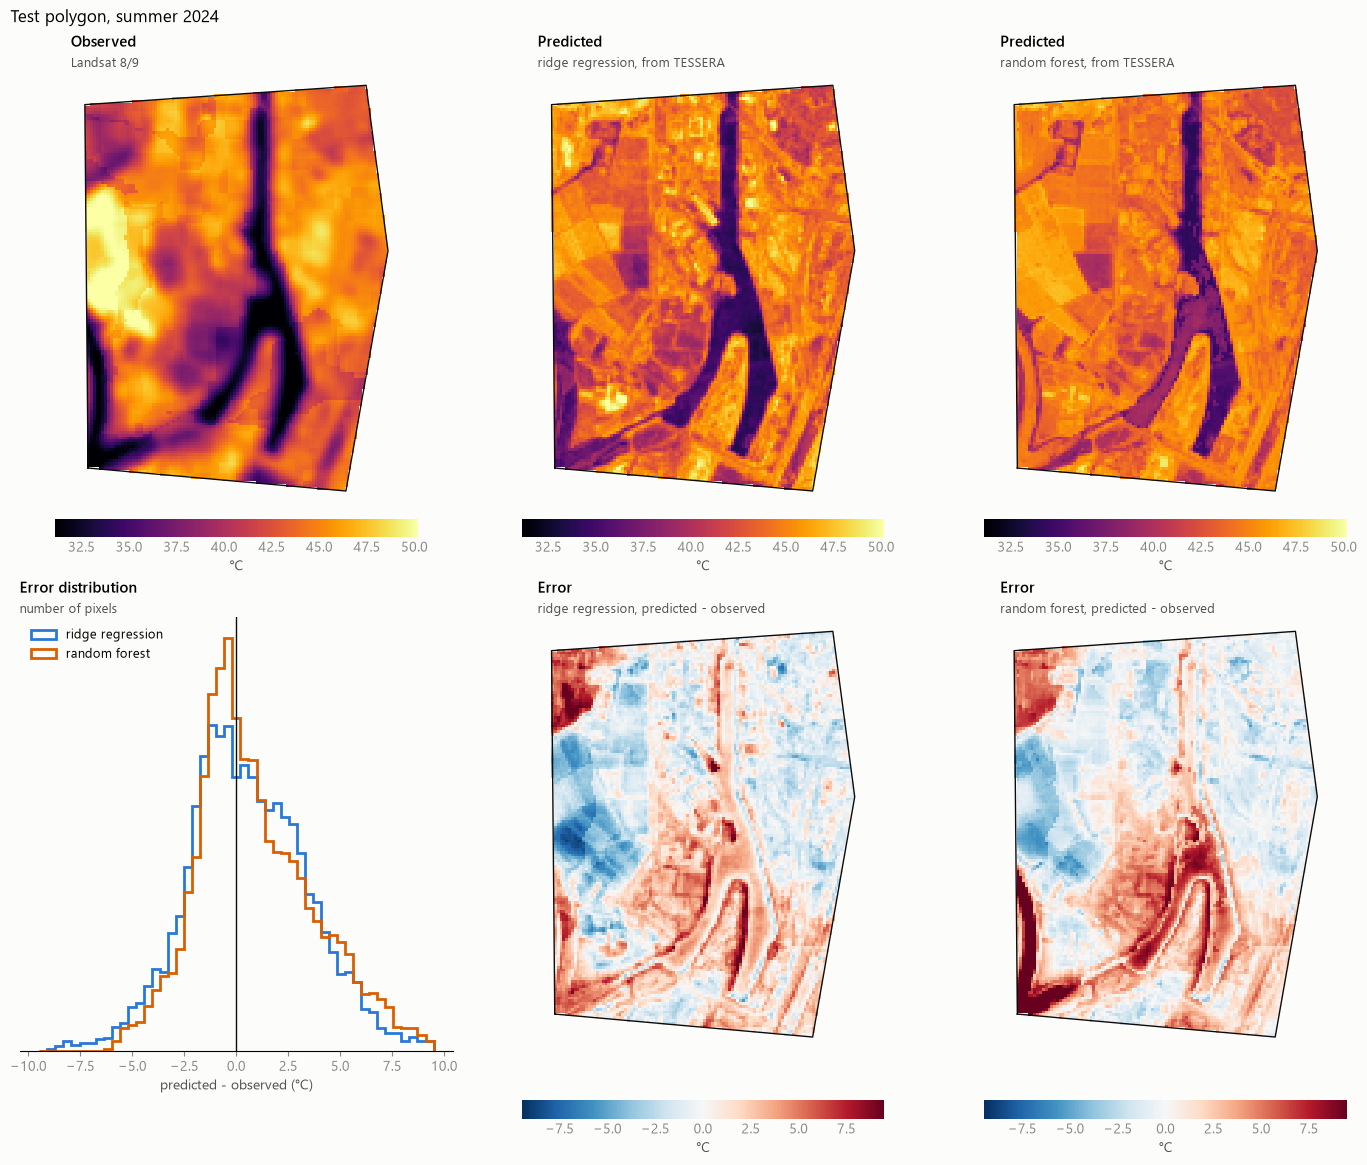

In [15]:
def to_map(values: np.ndarray, where: np.ndarray, like: xr.DataArray) -> xr.DataArray:
    # Put one value per table row back on the map grid; NaN elsewhere.
    grid = np.full(where.shape, np.nan)
    grid[where] = values
    return like.copy(data=grid)


def add_bar(fig, ax, mesh):
    bar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.8, pad=0.02)
    bar.set_label("°C", color=INK_SECONDARY)
    bar.outline.set_visible(False)
    bar.ax.tick_params(colors=INK_MUTED, length=0)


shown = ["ridge regression", "random forest"]
observed = to_map(y_test, test_where, lst["test"])
predicted = {name: to_map(predictions[name], test_where, lst["test"]) for name in shown}
errors = {name: predicted[name] - observed for name in shown}

outline = outline_on_grid(TEST_WKT, lst["test"])
heat = dict(cmap="inferno", vmin=np.percentile(y_test, 2), vmax=np.percentile(y_test, 98))
limit = max(float(np.nanpercentile(np.abs(e), 98)) for e in errors.values())
diverging = dict(cmap="RdBu_r", vmin=-limit, vmax=limit)

fig, axes = plt.subplots(2, 3, figsize=(14, 11.5), layout="constrained")
mesh = axes[0, 0].pcolormesh(observed.x, observed.y, observed, shading="nearest", **heat)
style_map(axes[0, 0], outline, "Observed", "Landsat 8/9")
add_bar(fig, axes[0, 0], mesh)

# Bottom left: how the errors of the two models are distributed.
ax = axes[1, 0]
bins = np.linspace(-limit, limit, 50)
for name, colour in zip(shown, (TRAIN_COLOUR, TEST_COLOUR), strict=True):
    ax.hist(
        errors[name].values[test_where],
        bins=bins,
        histtype="step",
        linewidth=2,
        color=colour,
        label=name,
    )
ax.axvline(0, color=INK_PRIMARY, linewidth=1)
ax.set_title("Error distribution\n", loc="left", fontsize=11, fontweight="semibold")
ax.text(0, 1.01, "number of pixels", transform=ax.transAxes, color=INK_SECONDARY, fontsize=9)
ax.set_xlabel("predicted - observed (°C)", color=INK_SECONDARY)
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.tick_params(colors=INK_MUTED)
ax.set_box_aspect(1)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.set_yticks([])

for col, name in enumerate(shown, start=1):
    da = predicted[name]
    mesh = axes[0, col].pcolormesh(da.x, da.y, da, shading="nearest", **heat)
    style_map(axes[0, col], outline, "Predicted", f"{name}, from TESSERA")
    add_bar(fig, axes[0, col], mesh)
    da = errors[name]
    mesh = axes[1, col].pcolormesh(da.x, da.y, da, shading="nearest", **diverging)
    style_map(axes[1, col], outline, "Error", f"{name}, predicted - observed")
    add_bar(fig, axes[1, col], mesh)
fig.suptitle(f"Test polygon, summer {YEAR}", x=0.01, ha="left", fontsize=12)
plt.show()

Where do the errors cluster?

- **Along the river banks** (red stripes): the predictions are sharper than the
  observations. The embeddings come from 10 m Sentinel-2 pixels, so the model draws a
  crisp river; Landsat's 100 m thermal pixels mix the cool water with the banks, so in the
  observations the river looks wider and its banks cooler. Part of this "error" is the
  target being blurrier than the inputs, not the model being wrong.
- **On the hottest fields** (blue patches in the west): bare, dry fields reach 50 °C, more
  than almost anything in the training polygon, and both models predict them too cool, the
  forest more so.
- **On a few fields predicted too hot**, like the one in the north-west corner: they were
  cool in summer 2024, perhaps irrigated, but look like the hot dry fields to the model.
  An embedding summarises the whole year, and a field's summer can differ from what the
  rest of its year suggests.
- The rest, the city and most fields, is within a degree or two.

The scatter plots show the same from another angle.

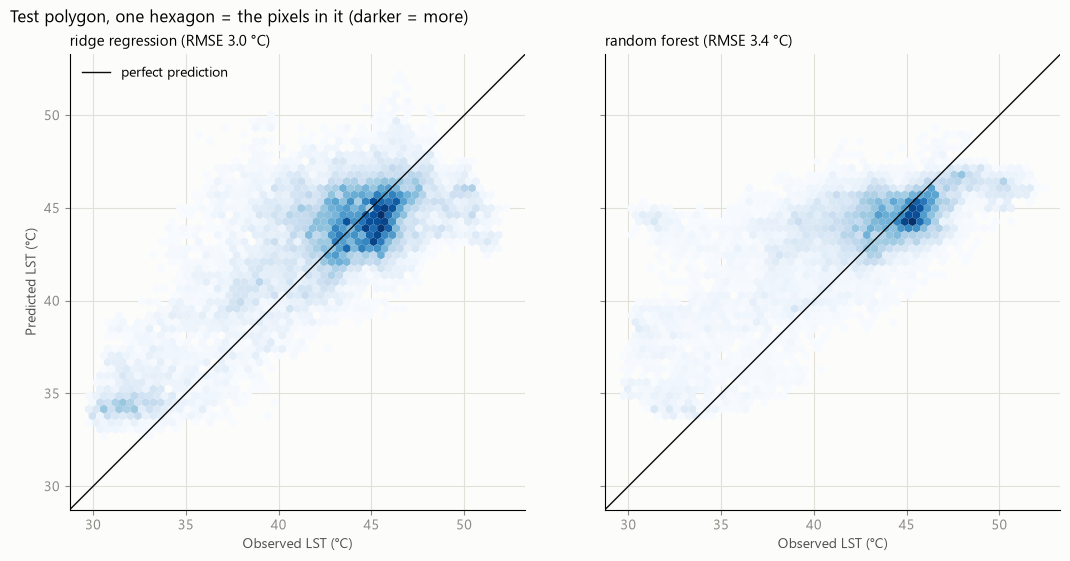

In [16]:
lims = [y_test.min() - 1, y_test.max() + 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), layout="constrained", sharey=True)
for ax, name in zip(axes, shown, strict=True):
    ax.hexbin(
        y_test,
        predictions[name],
        gridsize=60,
        cmap="Blues",
        mincnt=1,
        linewidths=0,
        extent=lims + lims,
    )
    ax.plot(lims, lims, color=INK_PRIMARY, linewidth=1, label="perfect prediction")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Observed LST (°C)", color=INK_SECONDARY)
    ax.set_aspect("equal")
    ax.grid(True, color=GRID)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=INK_MUTED)
    rmse = neighbour[name]["RMSE (°C)"]
    ax.set_title(f"{name} (RMSE {rmse:.1f} °C)", loc="left", fontsize=11)
axes[0].set_ylabel("Predicted LST (°C)", color=INK_SECONDARY)
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle(
    "Test polygon, one hexagon = the pixels in it (darker = more)", x=0.01, ha="left", fontsize=12
)
plt.show()

Both clouds are flatter than the 1:1 line: the models predict the cool pixels too warm
and the hot pixels too cool, **shrinking towards the mean** of the training data. That is
typical of regression models, and the forest, which can only average training
temperatures, shows it most: its predictions stop at the hottest and coolest training
values.

## 9. Take-aways and things to try

- A year of Sentinel-1/2 summarised by TESSERA carries a lot of information about surface
  temperature, although neither satellite measures it: the embedding knows whether a pixel
  is a roof, a tree, an irrigated field, bare soil or water, and those set the temperature.
- How you split the data decides the score you report. Random pixel splits overestimate
  accuracy; hold out blocks or, better, whole areas, and check that the training data
  cover the range of conditions you want to predict.
- The model learnt *late mornings of summer 2024 in Seville*. Temperature depends on the
  weather, so it will not transfer as it is to another summer or another climate.

Things to try:

1. **Swap the roles** of the two polygons. The test polygon has the wider range of
   temperatures: does training on it give a better model for the other one?
2. **Match the resolutions**: average the temperature and the embeddings onto a 90 m grid
   (3 x 3 Landsat pixels, closer to the thermal sensor's 100 m) before building the tables.
   Do the river-bank errors shrink?
3. **Fewer labels**: fit on a random 1 %, 5 %, 20 % of the training pixels. How many
   labelled pixels does the embedding need?
4. **Another target**: replace the temperature with the summer NDVI from Sentinel-2
   (`openeo` driver, see `polygon_ndvi_lst_soil_moisture.ipynb`). Is a variable that
   TESSERA *did* see easier to learn?
5. **Another year**: train on 2023 (embeddings and temperature) and test on 2024.